## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## Load Data and Take Sample

In [2]:
data = pd.read_csv("cars_clean.csv")
data = data.sample(n=min(5000, len(data)), random_state=42).reset_index(drop=True)
data.shape

(5000, 10)

## Select Features and Scale

In [3]:
features = ["price", "age", "mileage", "tax", "mpg", "engineSize"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])

## PCA Explained Variance

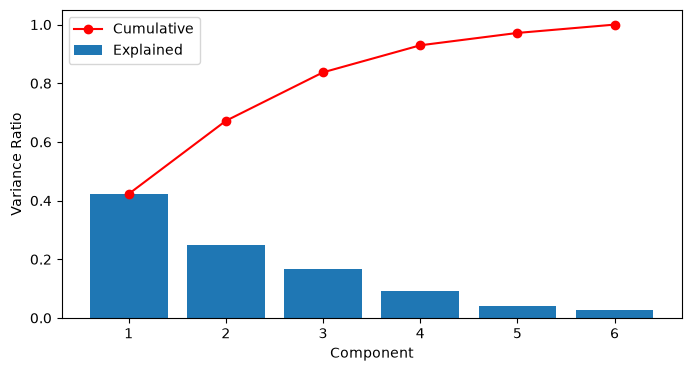

In [4]:
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(explained) + 1), explained, label="Explained")
plt.plot(range(1, len(explained) + 1), cumulative, marker="o", color="red", label="Cumulative")
plt.xlabel("Component")
plt.ylabel("Variance Ratio")
plt.legend()
plt.show()

## PCA with 2 Components

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
data["pca1"] = X_pca[:, 0]
data["pca2"] = X_pca[:, 1]
print("Variance covered:", pca.explained_variance_ratio_.sum().round(3))

Variance covered: 0.672


## PCA Loadings

In [6]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2)
loadings

,PC1,PC2
price,0.52,0.17
age,-0.44,0.49
mileage,-0.43,0.52
tax,0.38,0.21
mpg,-0.34,-0.26
engineSize,0.31,0.60


## t-SNE

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
data["tsne1"] = X_tsne[:, 0]
data["tsne2"] = X_tsne[:, 1]

## PCA vs t-SNE Plot

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(data["pca1"], data["pca2"], c=data["price"], cmap="viridis", s=5)
ax[0].set_title("PCA")
ax[1].scatter(data["tsne1"], data["tsne2"], c=data["price"], cmap="viridis", s=5)
ax[1].set_title("t-SNE")
plt.show()

## Save Reduced Data

In [ ]:
data.to_csv("reduced.csv", index=False)